# Showing the data via scanpy

In [2]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
adata = sc.read_h5ad("./source_data/seurat_curated_6dpf.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 30850 × 64955
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version'
    obsm: 'X_pca', 'X_umap'
    layers: 'RNA'


I have a 'RNA' layers instead of counts.

In [4]:
adata.layers['counts'] = adata.layers.pop('RNA')
adata.X = adata.layers['counts'].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

I do not need to redo the dimensionality reduction process, I saved it from Seurat...

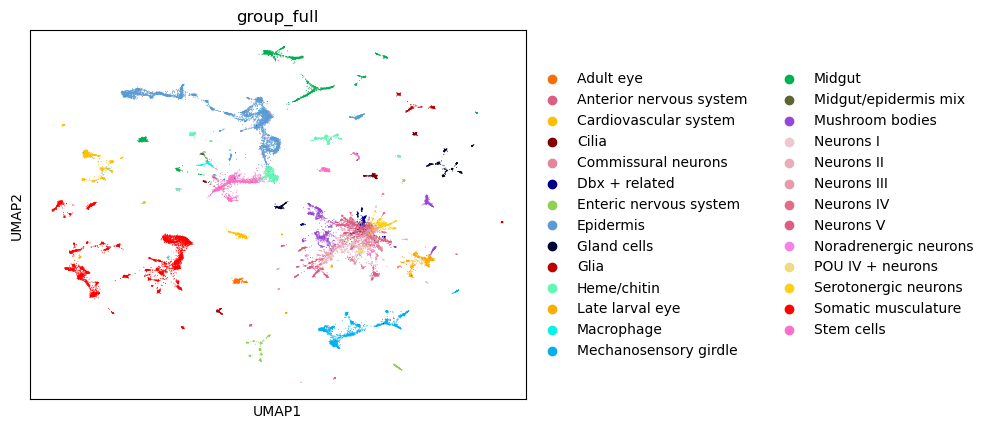

In [5]:
# I already have a defined color map
palette_dict = pd.Series(adata.obs['group_color'].values, index=adata.obs['group_full']).to_dict()
sc.pl.umap(
    adata,
    color="group_full",
    palette=palette_dict,
    size=2,
)

**In terms of metadata we care about:**
* `curated_high_res_annotations`:  Detlev's ~250 cell types (except 3 he likes but that are not in this curated object)
* `group_full`: Detlev's 20 or so big grouping, neurons are a bit hazy

I will rename my features to `XLOC | symbol`.

In [6]:
genes_metadata = pd.read_csv("./prepped_data/genes_metadata.tsv", sep="\t")
genes_metadata

,Unnamed: 0,ProsPR gene,Published name,pdumV2-1,Platybrowser name,XLOC,XLOC_full
0,0,Glt1,Glt1,XLOC_001410,glt1,XLOC-001410,XLOC-001410 | glt1
1,2,ANPRA,NaN,XLOC_025950,anpra,XLOC-025950,XLOC-025950 | anpra
2,4,AP2,ap2,XLOC_002429,ap2,XLOC-002429,XLOC-002429 | ap2
3,5,ASCb,ASCb,XLOC_008377,ascb,XLOC-008377,XLOC-008377 | ascb
4,6,AllCR1,NaN,XLOC_022100,allcr1,XLOC-022100,XLOC-022100 | allcr1
...,...,...,...,...,...,...,...
171,197,brn124,NaN,XLOC_005393,brn124,XLOC-005393,XLOC-005393 | brn124
172,198,nompc3,NaN,XLOC_002090,nompc3,XLOC-002090,XLOC-002090 | nompc3
173,199,pkd1,PKD1-1,XLOC_027897,pkd1,XLOC-027897,XLOC-027897 | pkd1
174,200,pkd2,PKD2-1,XLOC_026080,pkd2,XLOC-026080,XLOC-026080 | pkd2


In [7]:
genes_lookup = dict(zip(genes_metadata['XLOC'], genes_metadata['XLOC_full']))
genes_lookup

{'XLOC-001410': 'XLOC-001410 | glt1',
 'XLOC-025950': 'XLOC-025950 | anpra',
 'XLOC-002429': 'XLOC-002429 | ap2',
 'XLOC-008377': 'XLOC-008377 | ascb',
 'XLOC-022100': 'XLOC-022100 | allcr1',
 'XLOC-025660': 'XLOC-025660 | allcr2',
 'XLOC-044659': 'XLOC-044659 | arx',
 'XLOC-004258': 'XLOC-004258 | ash',
 'XLOC-056544': 'XLOC-056544 | barh1',
 'XLOC-003898': 'XLOC-003898 | beta3',
 'XLOC-009861': 'XLOC-009861 | bmpr1',
 'XLOC-000129': 'XLOC-000129 | brn3a',
 'XLOC-028320': 'XLOC-028320 | coe',
 'XLOC-026597': 'XLOC-026597 | chat',
 'XLOC-021496': 'XLOC-021496 | chx10',
 'XLOC-003551': 'XLOC-003551 | dach',
 'XLOC-018534': 'XLOC-018534 | dbhlike',
 'XLOC-020366': 'XLOC-020366 | dopard2',
 'XLOC-053880': 'XLOC-053880 | pgam',
 'XLOC-015543': 'XLOC-015543 | upp',
 'XLOC-008954': 'XLOC-008954 | unc22',
 'XLOC-014514': 'XLOC-014514 | ndus1',
 'XLOC-021313': 'XLOC-021313 | odo2',
 'XLOC-018549': 'XLOC-018549 | fxl21',
 'XLOC-012281': 'XLOC-012281 | ryr2',
 'XLOC-001169': 'XLOC-001169 | ppib'

I only keep Platybrowser features and I make sure I don't have unknown XLOC.

In [8]:
assert(not set(genes_lookup.keys()).difference(set(adata.var_names.to_list())))
subset_adata = adata[:, adata.var_names.isin(genes_lookup.keys())].copy()
subset_adata

AnnData object with n_obs × n_vars = 30850 × 174
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version', 'log1p', 'group_full_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'

In [9]:
subset_adata.var['XLOC'] = subset_adata.var_names
subset_adata.var_names = subset_adata.var_names.to_series().map(genes_lookup).tolist()

In [10]:
print(subset_adata.var_names)

Index(['XLOC-000033 | hand', 'XLOC-000129 | brn3a', 'XLOC-000131 | trk',
       'XLOC-000375 | hcn1', 'XLOC-000555 | gcb', 'XLOC-000718 | kv33b',
       'XLOC-000791 | nov29', 'XLOC-000875 | syt', 'XLOC-000971 | twist',
       'XLOC-001169 | ppib',
       ...
       'XLOC-064375 | bca1', 'XLOC-064638 | gpcr203', 'XLOC-066432 | vegfr',
       'XLOC-067105 | grm7', 'XLOC-067814 | rims', 'XLOC-067936 | psmf1',
       'XLOC-068990 | kv33e', 'XLOC-069315 | trpv5', 'XLOC-026293 | ato2',
       'XLOC-043332 | gpcr2'],
      dtype='object', length=174)


Pseudobulking is done like this:

In [11]:
platybrowser_aggregated = sc.get.aggregate(subset_adata, 
                                           by=["group_full", "curated_high_res_annotations"], 
                                           func=["sum", "count_nonzero"],layer="counts")
platybrowser_aggregated

AnnData object with n_obs × n_vars = 267 × 174
    obs: 'group_full', 'curated_high_res_annotations'
    var: 'XLOC'
    layers: 'sum', 'count_nonzero'

I will do a giant dotplot of what we have for Platybrowser. Let's define some arguments we want to play with from https://scanpy.readthedocs.io/en/stable/api/generated/classes/scanpy.pl.DotPlot.html
I will reuse them later.

In [12]:
extra_args = {
    "expression_cutoff": 0,
    "standard_scale": "group", # None #  "var"
    "mean_only_expressed": False
}

You get the big group names and the the clades. We could play with the order, but not for now. Some markers are super high everywhere, others like `unc-22` are good markers for a group like `Somatic musculature`. Some are super sparse.

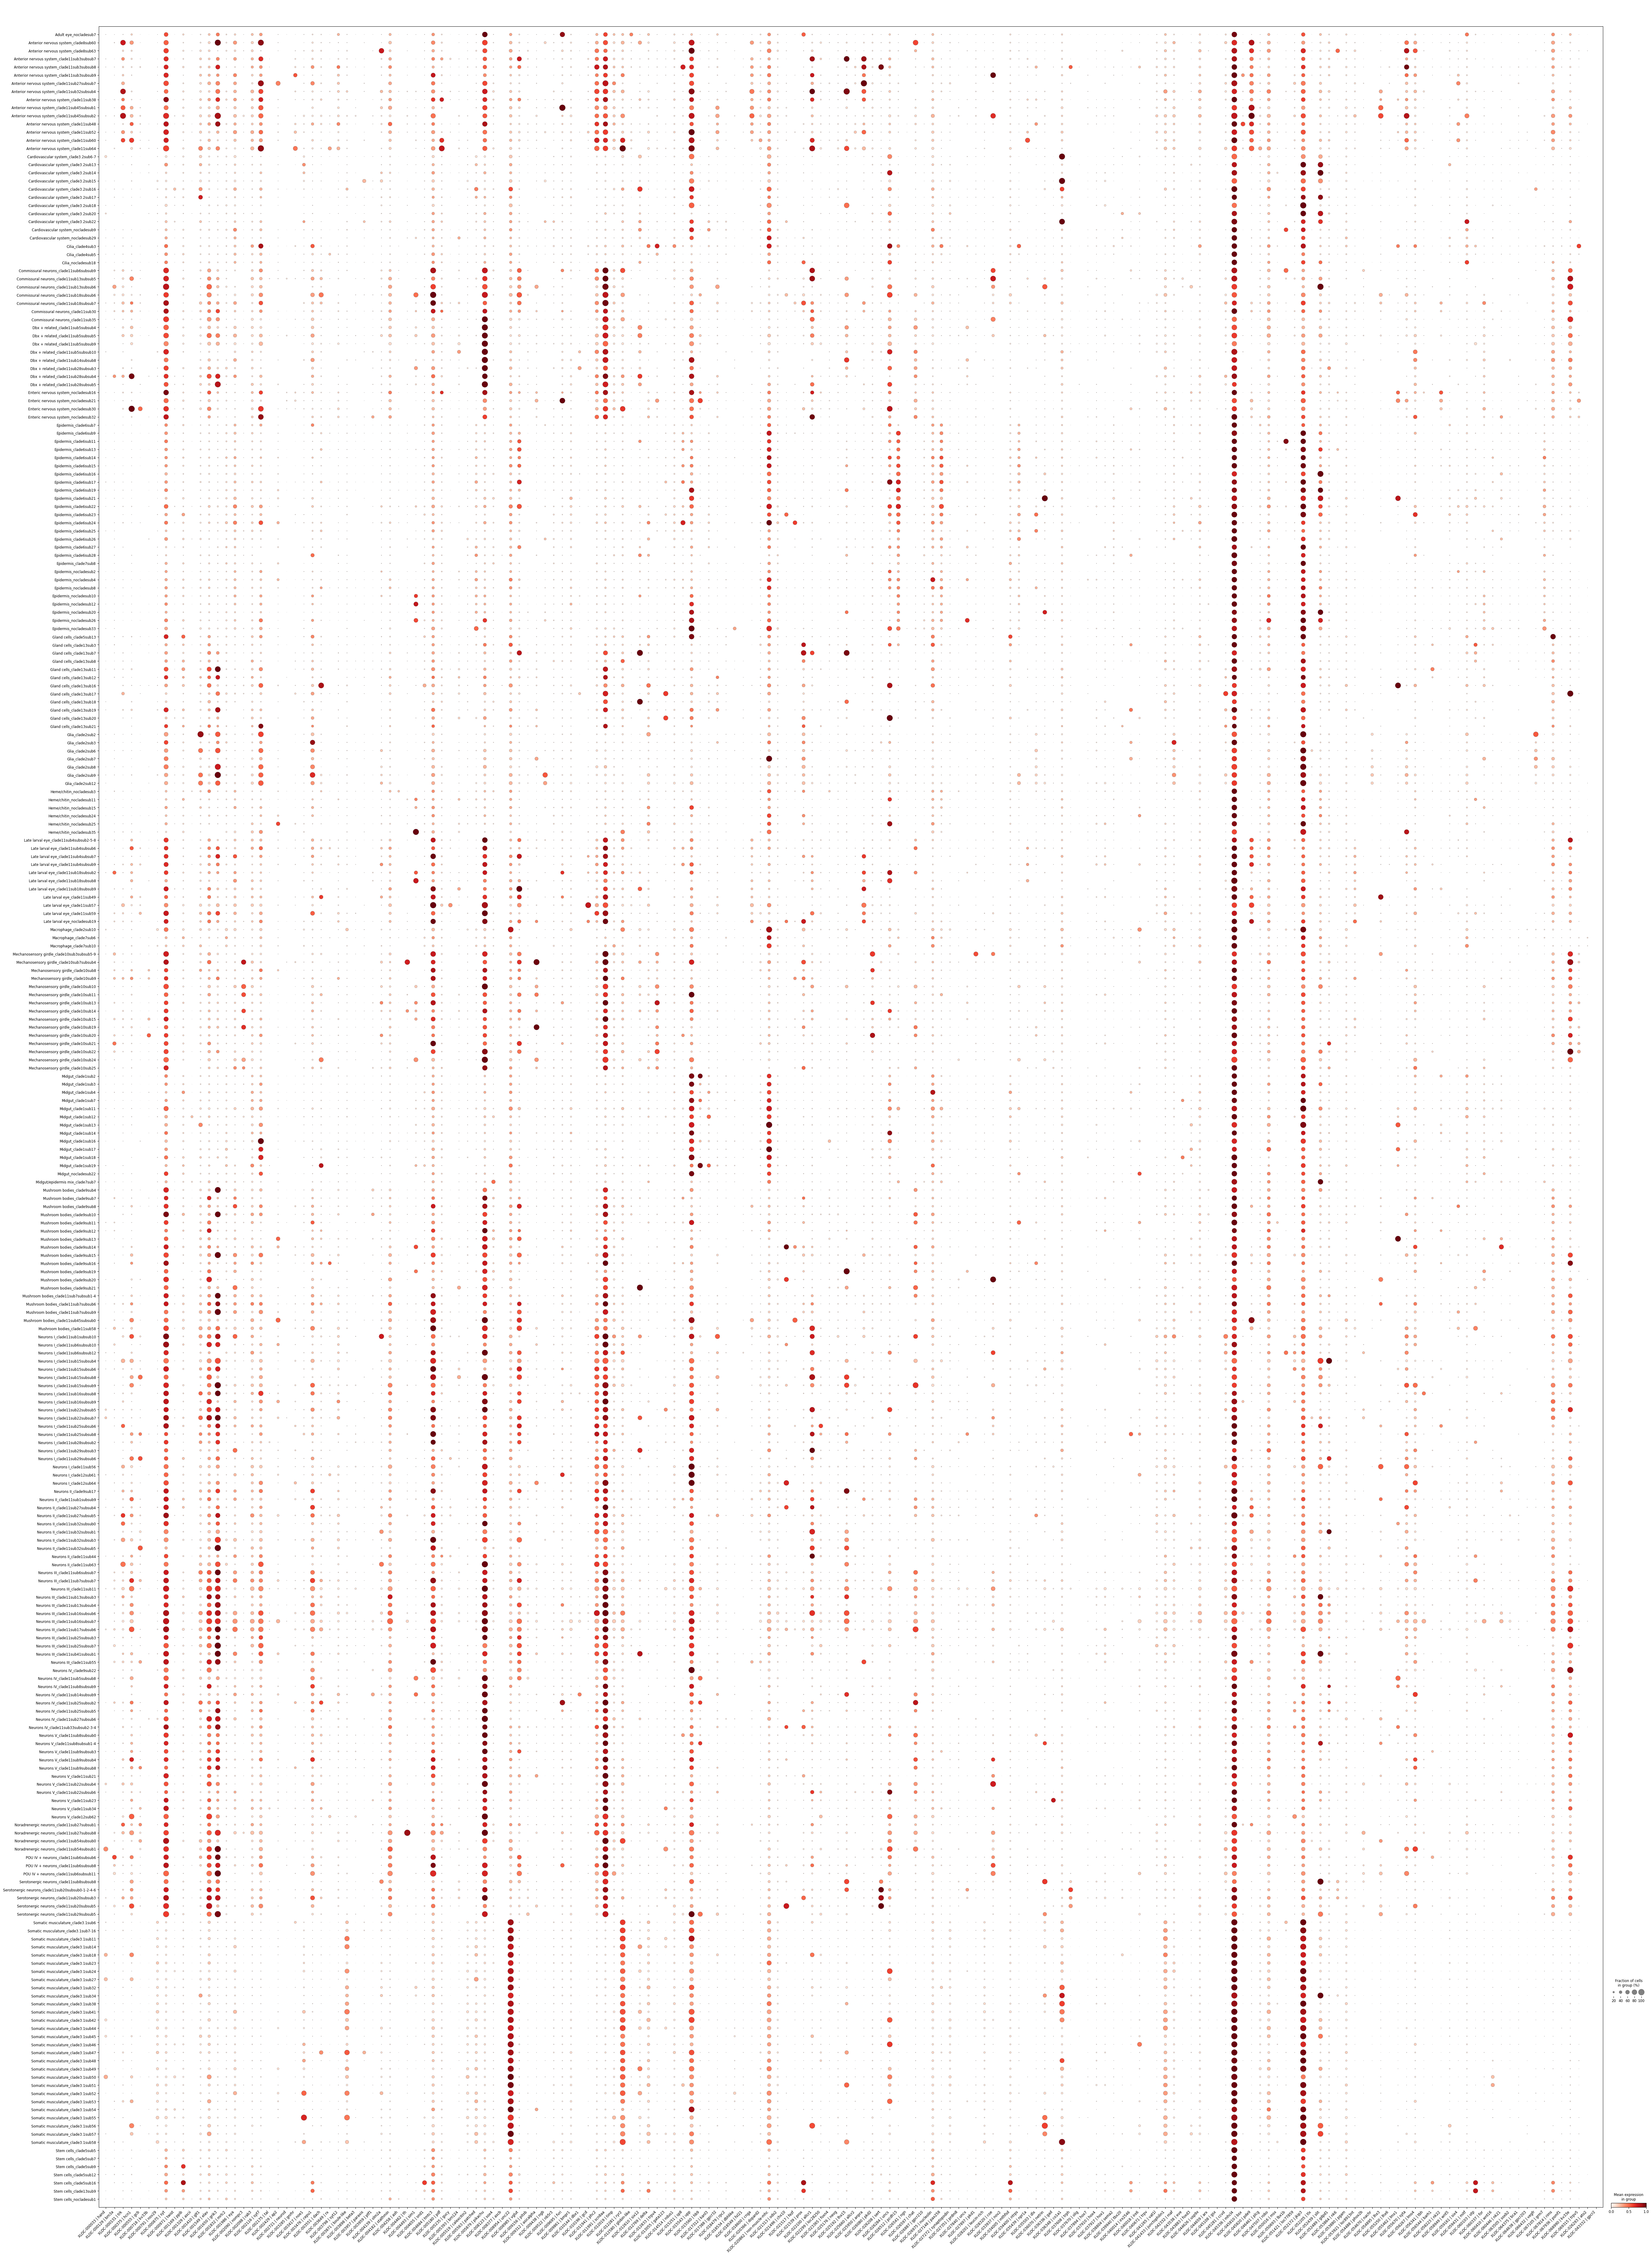

In [13]:
platybrowser_dotplot = sc.pl.dotplot(
    subset_adata, 
    subset_adata.var_names.to_list(),
    groupby=["group_full", "curated_high_res_annotations"],
    return_fig=True,
    **extra_args
)

# Prettier plots
platybrowser_dotplot .make_figure()
ax = platybrowser_dotplot .get_axes()['mainplot_ax']
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

We can access info from the dotplot.

In [14]:
platybrowser_dotplot = sc.pl.dotplot(
    subset_adata, 
    subset_adata.var_names.to_list(),
    groupby=["group_full", "curated_high_res_annotations"], 
    return_fig=True,
    **extra_args
)

Following https://github.com/scverse/scanpy/blob/1.11.3/src/scanpy/plotting/_dotplot.py#L822-L1031 I can extract the dotplot information

In [15]:
obs_bool = platybrowser_dotplot.obs_tidy > extra_args["expression_cutoff"]

# dot_size -> fraction of cells, never changes
dot_size_df = (
    obs_bool.groupby(level=0, observed=True).sum()
        / obs_bool.groupby(level=0, observed=True).count()
)

# dot_color -> strength of expression but with scaled values, scaling can change!
if extra_args["mean_only_expressed"]:
    dot_color_df = (
        platybrowser_dotplot.obs_tidy.mask(~obs_bool)
            .groupby(level=0, observed=True)
            .mean()
            .fillna(0)
        )
else:
    dot_color_df = platybrowser_dotplot.obs_tidy.groupby(level=0, observed=True).mean()

# dot_color depends on the chosen scale
standard_scale = extra_args["standard_scale"]
if standard_scale == "group":
    dot_color_df = dot_color_df.sub(dot_color_df.min(1), axis=0)
    dot_color_df = dot_color_df.div(dot_color_df.max(1), axis=0).fillna(0)
elif standard_scale == "var":
    dot_color_df -= dot_color_df.min(0)
    dot_color_df = (dot_color_df / dot_color_df.max(0)).fillna(0)
elif standard_scale is None:
    pass
else:
    print("Unknown type for standard_scale, ignored")

Here is what you end up with:

In [16]:
dot_color_df.head()   # mean of SCALED expression value

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Adult eye_nocladesub7,0.022198,0.015248,0.042993,0.169736,0.005995,0.001405,0.018079,0.578787,0.004623,0.149039,...,0.024629,0.004966,0.007503,0.020178,0.376029,0.019368,0.229301,0.007010,0.001754,0.0
Anterior nervous system_clade8sub60,0.000000,0.036712,0.746187,0.354410,0.006493,0.000000,0.007643,0.530321,0.000000,0.057879,...,0.013768,0.000000,0.000000,0.012104,0.314606,0.013147,0.064020,0.000000,0.000000,0.0
Anterior nervous system_clade8sub63,0.000000,0.000000,0.130882,0.117175,0.000000,0.000000,0.000000,0.618841,0.000000,0.091991,...,0.000000,0.000000,0.029157,0.031141,0.329229,0.012698,0.044490,0.028472,0.016313,0.0
Anterior nervous system_clade11sub3subsub7,0.036154,0.007014,0.396268,0.135287,0.012570,0.000000,0.007308,0.676243,0.008495,0.095452,...,0.006528,0.007055,0.000000,0.000000,0.291035,0.007055,0.051407,0.030602,0.000000,0.0
Anterior nervous system_clade11sub3subsub8,0.035521,0.021395,0.156105,0.103161,0.105439,0.000000,0.028565,0.706278,0.000000,0.140166,...,0.064383,0.013651,0.016149,0.015453,0.328186,0.038648,0.124772,0.012037,0.000000,0.0


In [17]:
dot_size_df.head()  # Fraction of cells expressing

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Adult eye_nocladesub7,0.030043,0.019313,0.051502,0.197425,0.008584,0.002146,0.021459,0.622318,0.006438,0.180258,...,0.034335,0.006438,0.008584,0.025751,0.442060,0.027897,0.272532,0.010730,0.002146,0.0
Anterior nervous system_clade8sub60,0.000000,0.076923,0.830769,0.553846,0.015385,0.000000,0.015385,0.753846,0.000000,0.092308,...,0.030769,0.000000,0.000000,0.030769,0.507692,0.030769,0.123077,0.000000,0.000000,0.0
Anterior nervous system_clade8sub63,0.000000,0.000000,0.189189,0.162162,0.000000,0.000000,0.000000,0.783784,0.000000,0.162162,...,0.000000,0.000000,0.054054,0.054054,0.513514,0.027027,0.054054,0.054054,0.027027,0.0
Anterior nervous system_clade11sub3subsub7,0.042105,0.010526,0.421053,0.168421,0.021053,0.000000,0.010526,0.736842,0.010526,0.115789,...,0.010526,0.010526,0.000000,0.000000,0.368421,0.010526,0.073684,0.042105,0.000000,0.0
Anterior nervous system_clade11sub3subsub8,0.035714,0.035714,0.178571,0.125000,0.125000,0.000000,0.035714,0.696429,0.000000,0.196429,...,0.071429,0.017857,0.017857,0.017857,0.392857,0.053571,0.178571,0.017857,0.000000,0.0


In [18]:
average_absolute_exp = pd.DataFrame(
    platybrowser_aggregated.layers['sum'],
    index=platybrowser_aggregated.obs_names,
    columns=platybrowser_aggregated.var_names
)

average_absolute_exp.head()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
Adult eye_nocladesub7,14.0,10.0,37.0,157.0,4.0,1.0,13.0,542.0,3.0,105.0,...,18.0,3.0,4.0,15.0,292.0,14.0,197.0,6.0,1.0,0.0
Anterior nervous system_clade8sub60,0.0,6.0,222.0,66.0,1.0,0.0,1.0,106.0,0.0,8.0,...,2.0,0.0,0.0,2.0,57.0,2.0,8.0,0.0,0.0,0.0
Anterior nervous system_clade8sub63,0.0,0.0,12.0,8.0,0.0,0.0,0.0,64.0,0.0,6.0,...,0.0,0.0,2.0,2.0,26.0,1.0,10.0,2.0,1.0,0.0
Anterior nervous system_clade11sub3subsub7,6.0,1.0,88.0,29.0,2.0,0.0,1.0,151.0,1.0,14.0,...,1.0,1.0,0.0,0.0,57.0,1.0,9.0,5.0,0.0,0.0
Anterior nervous system_clade11sub3subsub8,2.0,2.0,15.0,14.0,10.0,0.0,2.0,98.0,0.0,12.0,...,7.0,1.0,1.0,1.0,34.0,3.0,11.0,2.0,0.0,0.0


We load Platybrowser

In [19]:
em_unsorted_cols = pd.read_table("./prepped_data/platybrowser_counts.tsv", index_col="label_id")
# forgot to do this, I want alphabetical
em = em_unsorted_cols .sort_index(axis=1)
em.head()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-060446 | nk21,XLOC-063505 | soxb2,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5
label_id,,,,,,,,,,,,,,,,,,,,,
1.0,0.00146,0.001112,0.000066,0.002051,0.00648,0.001305,0.000604,0.037809,0.002245,0.0,...,0.009226,0.00068,0.000043,0.012019,0.01309,0.480433,0.009885,0.000325,0.003868,0.023110
2.0,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.00000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000
3.0,0.00000,0.099017,0.000000,0.003640,0.00000,0.045504,0.000000,0.017474,0.000000,0.0,...,0.002184,0.00000,0.000000,0.000000,0.00000,0.949399,0.000000,0.046596,0.001092,0.002184
4.0,0.00000,0.011179,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.282520,0.00000,0.000000,0.000000,0.00000,0.994919,0.000000,0.000000,0.000000,0.000000
5.0,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.00000,0.000000,0.000000,0.00000,0.111111,0.000000,0.000000,0.000000,0.000000


In [32]:
em.describe()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000971 | twist,XLOC-001169 | ppib,XLOC-001329 | asci,XLOC-001329 | ascii,...,XLOC-059161 | six4,XLOC-060103 | otp,XLOC-060337 | for,XLOC-060410 | wnt16,XLOC-060446 | nk21,XLOC-063505 | soxb2,XLOC-064375 | bca1,XLOC-067105 | grm7,XLOC-067936 | psmf1,XLOC-069315 | trpv5
count,32699.000000,32699.00000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,...,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000
mean,0.033868,0.03728,0.016099,0.022723,0.105217,0.014800,0.043425,0.013717,0.026289,0.009737,...,0.015466,0.014762,0.048479,0.022851,0.015432,0.012909,0.012441,0.141337,0.030821,0.022701
std,0.158917,0.15533,0.103675,0.119528,0.261934,0.095981,0.169259,0.102245,0.124113,0.078002,...,0.094343,0.093329,0.198451,0.129130,0.104937,0.089945,0.094138,0.306049,0.135418,0.118421
min,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.029478,0.000000,0.000000
max,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## New results, looking at clustering

We read Detlev's ordering.

In [20]:
group_metadata = pd.read_table("/g/arendt/projects/10_platy_6dpf/data/annotations/subclade_ordering_color_scheme.tsv")
group_metadata["merged_info"] = group_metadata["group_full"] + "_" + group_metadata["sub_membership"] 
group_metadata.head()

,group_full,group_slug,group_color,sub_membership,notes,merged_info
0,Stem cells,stem_cells,#FF6EC7,clade5sub7,NaN,Stem cells_clade5sub7
1,Stem cells,stem_cells,#FF6EC7,clade13sub9,NaN,Stem cells_clade13sub9
2,Stem cells,stem_cells,#FF6EC7,clade5sub16,NaN,Stem cells_clade5sub16
3,Stem cells,stem_cells,#FF6EC7,clade5sub9,NaN,Stem cells_clade5sub9
4,Stem cells,stem_cells,#FF6EC7,nocladesub1,NaN,Stem cells_nocladesub1


It looks like it was all converted to a 0-1 scale for me!

In [21]:
em.describe()['XLOC-043332 | gpcr2']

count    32699.000000
mean         0.003222
std          0.047554
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: XLOC-043332 | gpcr2, dtype: float64

I follow Detlev's ordering.

In [22]:
average_absolute_exp = average_absolute_exp.reindex(group_metadata["merged_info"].to_list())
average_absolute_exp.head()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
Stem cells_clade5sub7,3.0,8.0,4.0,9.0,0.0,0.0,11.0,129.0,3.0,61.0,...,5.0,0.0,2.0,5.0,16.0,5.0,31.0,2.0,0.0,0.0
Stem cells_clade13sub9,1.0,0.0,4.0,4.0,0.0,1.0,0.0,41.0,0.0,41.0,...,1.0,0.0,0.0,7.0,46.0,5.0,10.0,0.0,0.0,0.0
Stem cells_clade5sub16,0.0,2.0,2.0,3.0,1.0,0.0,2.0,45.0,1.0,112.0,...,0.0,0.0,0.0,2.0,41.0,2.0,18.0,2.0,0.0,0.0
Stem cells_clade5sub9,2.0,9.0,4.0,7.0,0.0,2.0,6.0,190.0,1.0,367.0,...,3.0,0.0,4.0,2.0,25.0,1.0,33.0,2.0,0.0,0.0
Stem cells_nocladesub1,21.0,35.0,29.0,18.0,5.0,3.0,19.0,256.0,11.0,259.0,...,23.0,0.0,12.0,54.0,62.0,23.0,65.0,12.0,1.0,0.0


We rescale single cell counts

In [23]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
average_absolute_exp[:] = scaler.fit_transform(average_absolute_exp)
average_absolute_exp.describe()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
count,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,...,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.0
mean,0.024300,0.037253,0.028928,0.018208,0.034457,0.018924,0.032738,0.027661,0.047255,0.067824,...,0.091091,0.025983,0.010112,0.039697,0.028194,0.077211,0.017059,0.021693,0.014981,0.0
std,0.103677,0.097647,0.076117,0.066254,0.108645,0.102432,0.099196,0.065563,0.116273,0.111877,...,0.139461,0.076533,0.064132,0.119607,0.067892,0.134894,0.065669,0.091102,0.076737,0.0
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,0.000000,0.004444,0.002857,0.001754,0.000000,0.000000,0.000000,0.007975,0.000000,0.013624,...,0.000000,0.000000,0.000000,0.000000,0.006446,0.000000,0.002304,0.000000,0.000000,0.0
50%,0.004739,0.008889,0.009524,0.005263,0.008696,0.000000,0.003984,0.014420,0.021277,0.029973,...,0.035714,0.000000,0.000000,0.004717,0.014504,0.038462,0.004864,0.004950,0.000000,0.0
75%,0.009479,0.026667,0.025714,0.014035,0.017391,0.008772,0.015936,0.029714,0.042553,0.068120,...,0.107143,0.000000,0.004444,0.018868,0.029009,0.076923,0.012929,0.009901,0.000000,0.0
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.0


Some columns have low or zero variance?

In [24]:
column_variances = average_absolute_exp.var(numeric_only=True)
column_variances.sort_values()[1:20]

XLOC-036336 | gad            0.003838
XLOC-036348 | co1a1          0.003849
XLOC-003898 | beta3          0.003926
XLOC-054488 | phox2b         0.003938
XLOC-037894 | hox7           0.003998
XLOC-012580 | globin-like    0.004003
XLOC-066432 | vegfr          0.004113
XLOC-045281 | ccvd           0.004185
XLOC-028320 | coe            0.004237
XLOC-011991 | scn8aa         0.004259
XLOC-037917 | hox1           0.004279
XLOC-000875 | syt            0.004298
XLOC-068990 | kv33e          0.004312
XLOC-000375 | hcn1           0.004390
XLOC-001410 | glt1           0.004452
XLOC-041265 | vat1l          0.004458
XLOC-009156 | pitxb          0.004463
XLOC-005879 | pikachu        0.004486
XLOC-001549 | elav           0.004501
dtype: float64

In [25]:
column_variances_em = em.var(numeric_only=True)
column_variances_em.sort_values()[1:40]

XLOC-012580 | globin-like    0.000574
XLOC-035439 | npr1a          0.000613
XLOC-059431 | mitf           0.000998
XLOC-017388 | gpcr32         0.001019
XLOC-027351 | prdm8          0.001073
XLOC-058223 | nk22           0.001209
XLOC-045810 | bsx            0.001214
XLOC-044659 | arx            0.001344
XLOC-012769 | delta          0.001516
XLOC-025660 | allcr2         0.001749
XLOC-003898 | beta3          0.001834
XLOC-005180 | pdf            0.001885
XLOC-026284 | uncs           0.001967
XLOC-052205 | tlx            0.001984
XLOC-043332 | gpcr2          0.002261
XLOC-064638 | gpcr203        0.002393
XLOC-008123 | sox4           0.002406
XLOC-005235 | gucy           0.002514
XLOC-026293 | ato2           0.002583
XLOC-055670 | syta           0.002598
XLOC-008377 | ascb           0.002629
XLOC-040014 | irx2546        0.002774
XLOC-009438 | ngb            0.002813
XLOC-018534 | dbhlike        0.002819
XLOC-056341 | tbh            0.002877
XLOC-052489 | gdpd1          0.003402
XLOC-067814 

In [30]:
zero_var_cols = average_absolute_exp.columns[average_absolute_exp.var() <= 0.005]
print("Found zero-variance columns for the single cell:", sorted(list(zero_var_cols)))
zero_var_cols_em = em.columns[em.var() <= 0.005]
print("Found zero-variance columns for the EM:", sorted(list(zero_var_cols_em)))
print(f"My overlap is {len([x for x in zero_var_cols_em if x in zero_var_cols])} IDs that I want to remove")
print(f"My total is {len(zero_var_cols) + len(zero_var_cols_em) - len([x for x in zero_var_cols_em if x in zero_var_cols])} IDs that I want to remove")
average_absolute_exp = average_absolute_exp.drop(columns= list(set(zero_var_cols.to_list() + zero_var_cols_em.to_list())))
em = em.drop(columns= list(set(zero_var_cols.to_list() + zero_var_cols_em.to_list())))

Found zero-variance columns for the single cell: ['XLOC-000375 | hcn1', 'XLOC-000875 | syt', 'XLOC-001410 | glt1', 'XLOC-001549 | elav', 'XLOC-001650 | grik3', 'XLOC-003285 | gnrhr', 'XLOC-003898 | beta3', 'XLOC-005879 | pikachu', 'XLOC-009156 | pitxb', 'XLOC-011941 | phc2', 'XLOC-011991 | scn8aa', 'XLOC-012580 | globin-like', 'XLOC-025192 | lhx15', 'XLOC-026208 | sert', 'XLOC-026597 | chat', 'XLOC-027351 | prdm8', 'XLOC-027897 | pkd1', 'XLOC-028320 | coe', 'XLOC-036336 | gad', 'XLOC-036348 | co1a1', 'XLOC-037608 | trph', 'XLOC-037894 | hox7', 'XLOC-037917 | hox1', 'XLOC-041265 | vat1l', 'XLOC-043332 | gpcr2', 'XLOC-045281 | ccvd', 'XLOC-045810 | bsx', 'XLOC-053864 | nk6', 'XLOC-054488 | phox2b', 'XLOC-055250 | lhx6', 'XLOC-066432 | vegfr', 'XLOC-067814 | rims', 'XLOC-068990 | kv33e']
Found zero-variance columns for the EM: ['XLOC-003285 | gnrhr', 'XLOC-003898 | beta3', 'XLOC-003957 | paraxis', 'XLOC-003959 | ptf1', 'XLOC-004258 | ash', 'XLOC-005180 | pdf', 'XLOC-005235 | gucy', 'XLOC-

<Figure size 2400x1600 with 0 Axes>

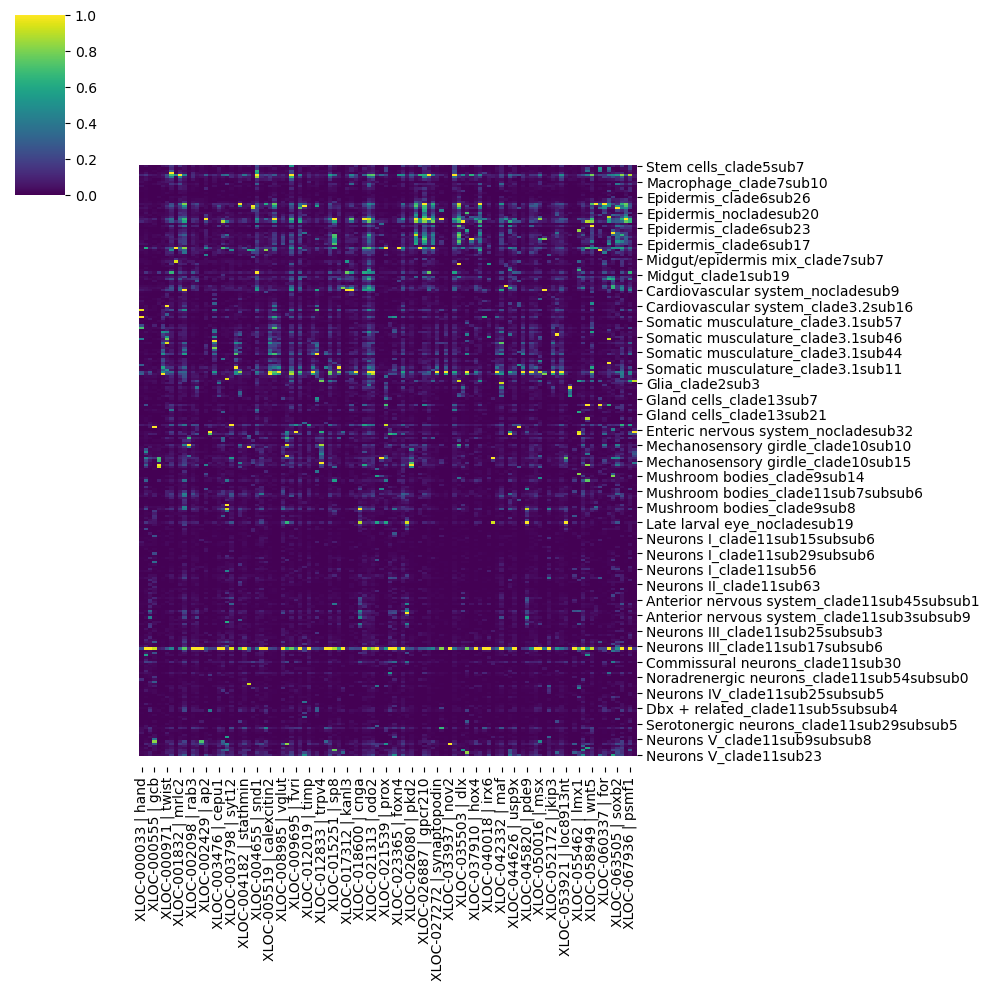

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(24, 16))

sns.clustermap(average_absolute_exp,
               col_cluster=False,
               row_cluster=False,
               cmap='viridis',
               annot=False,
               fmt='.2f')

plt.show()